# 01 - EDA

Looking at the four tables before building anything. Data comes from the postgres db
(run `python src/data_load.py` first). Names, emails and phones are dropped straight away.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

engine = create_engine(os.getenv("DATABASE_URL", "postgresql+psycopg2:///credit_risk"))

In [2]:
customers = pd.read_sql("SELECT * FROM customers", engine)
customers = customers.drop(columns=["first_name", "last_name", "email", "phone"])

credit = pd.read_sql("SELECT * FROM credit_history", engine)
loans = pd.read_sql("SELECT * FROM loan_applications", engine, parse_dates=["application_date", "decision_date"])
txns = pd.read_sql("SELECT * FROM transactions", engine, parse_dates=["transaction_date"])

for name, df in [("customers", customers), ("credit", credit), ("loans", loans), ("txns", txns)]:
    print(f"{name}: {df.shape}")

customers: (5000, 16)
credit: (5000, 14)
loans: (7500, 17)
txns: (40079, 8)


## Missing values

In [3]:
for name, df in [("customers", customers), ("credit", credit), ("loans", loans), ("txns", txns)]:
    miss = df.isna().sum()
    print(name, dict(miss[miss > 0]) or "none")

customers none
credit none
loans {'decision_date': np.int64(173), 'loan_default': np.int64(4097)}
txns none


Only two columns have gaps and both make sense:
- `decision_date` is empty for the 173 apps still Under Review
- `loan_default` is empty for anything not disbursed, so the model can only use disbursed loans

In [4]:
loans.groupby("approval_status")[["disbursed_flag", "loan_default"]].agg(["count", "sum"])

disbursed_flag       loan_default       
                         count   sum        count    sum
approval_status                                         
Approved                  3403  3403         3403  797.0
Rejected                  3924     0            0    0.0
Under Review               173     0            0    0.0

## Customers

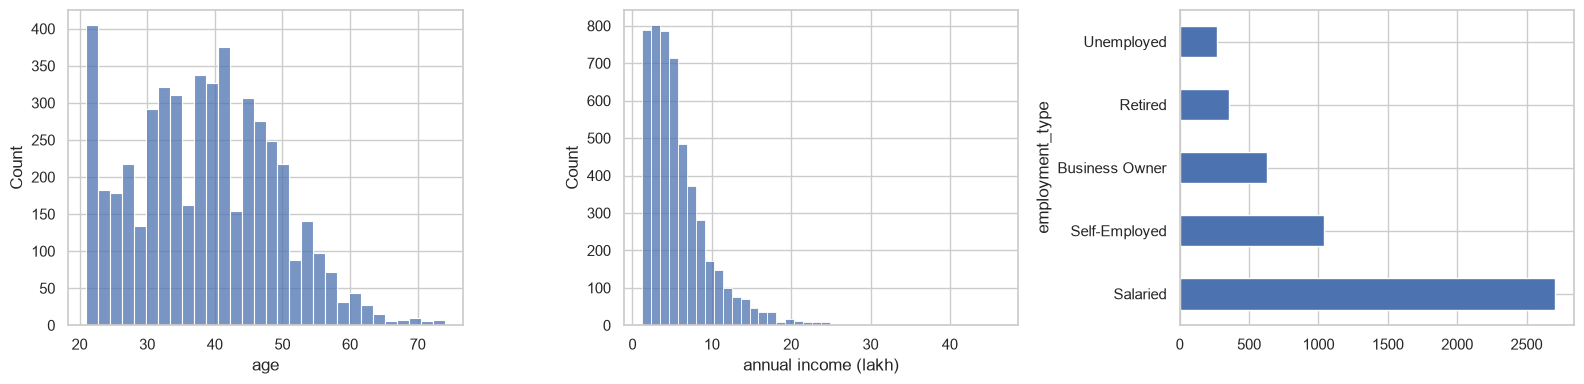

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(customers["age"], bins=30, ax=axes[0])
sns.histplot(customers["annual_income"] / 1e5, bins=40, ax=axes[1])
axes[1].set_xlabel("annual income (lakh)")
customers["employment_type"].value_counts().plot.barh(ax=axes[2])
plt.tight_layout()

In [6]:
customers['annual_income'].describe()

count    5.000000e+03
mean     5.795758e+05
std      4.225968e+05
min      1.200000e+05
25%      2.941750e+05
50%      4.748000e+05
75%      7.280500e+05
max      4.636900e+06
Name: annual_income, dtype: float64

Income is right skewed so a log transform could help for logistic regression later.

## Credit history

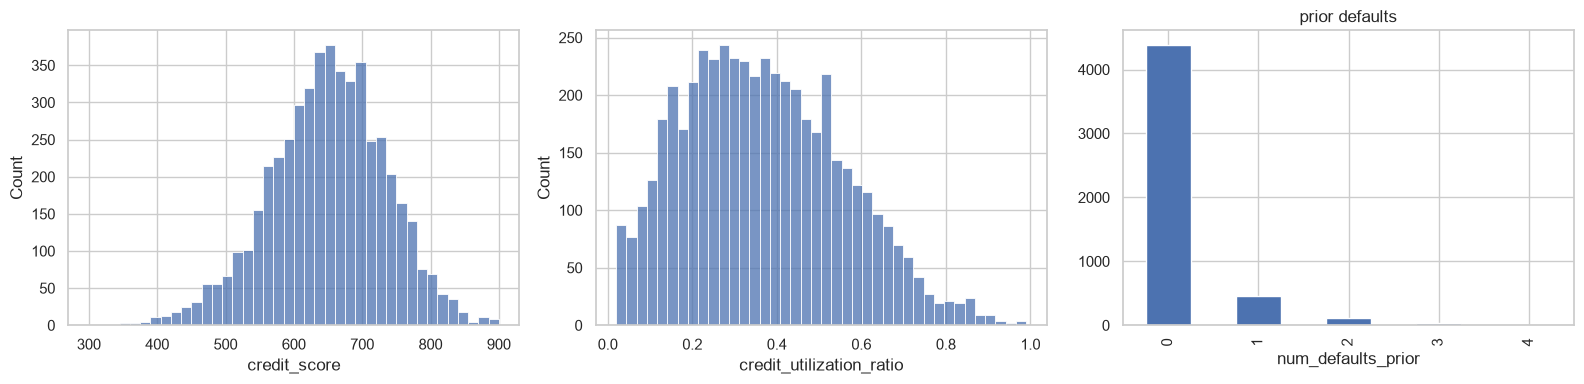

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(credit["credit_score"], bins=40, ax=axes[0])
sns.histplot(credit["credit_utilization_ratio"], bins=40, ax=axes[1])
credit["num_defaults_prior"].value_counts().sort_index().plot.bar(ax=axes[2], title="prior defaults")
plt.tight_layout()

In [8]:
credit.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,5000.0,648.934400,85.403960,300.00,595.000,652.000,706.000,900.00
num_open_accounts,5000.0,3.490400,1.848294,0.00,2.000,3.000,5.000,14.00
num_credit_inquiries_6m,5000.0,1.670400,1.326694,0.00,1.000,1.000,2.000,8.00
credit_utilization_ratio,5000.0,0.368043,0.187692,0.02,0.222,0.353,0.502,0.99
num_late_payments_30d,5000.0,1.293200,1.450260,0.00,0.000,1.000,2.000,9.00
num_late_payments_90d,5000.0,0.258400,0.586258,0.00,0.000,0.000,0.000,5.00
num_defaults_prior,5000.0,0.161800,0.486691,0.00,0.000,0.000,0.000,4.00
bankruptcies,5000.0,0.001800,0.042392,0.00,0.000,0.000,0.000,1.00
total_credit_limit,5000.0,319364.400000,276935.671025,25000.00,138000.000,243500.000,407000.000,3651000.00
total_outstanding_debt,5000.0,109584.300000,111665.552623,2500.00,40400.000,75300.000,139600.000,1682000.00


## Loan applications

approval rate (decided): 46.4 %


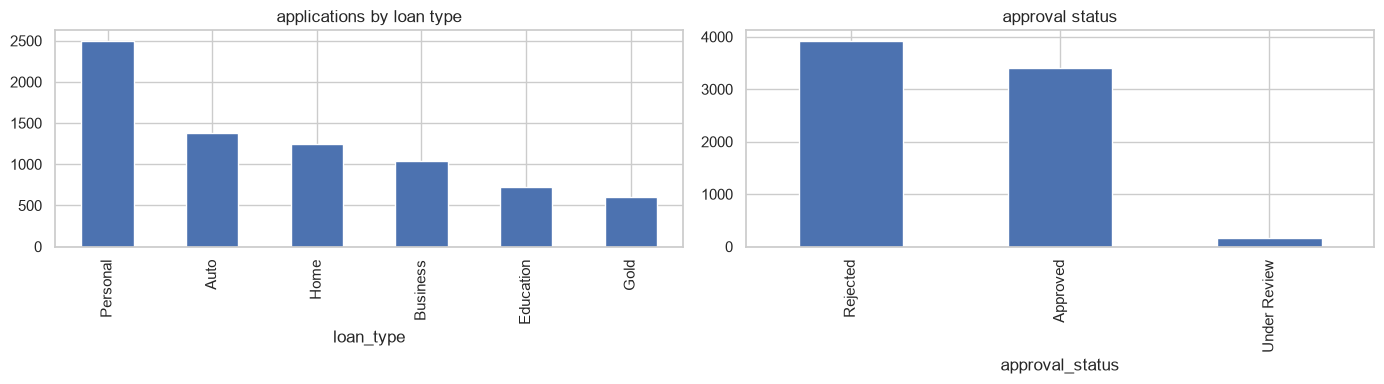

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
loans["loan_type"].value_counts().plot.bar(ax=axes[0], title="applications by loan type")
loans["approval_status"].value_counts().plot.bar(ax=axes[1], title="approval status")
plt.tight_layout()

decided = loans[loans["approval_status"] != "Under Review"]
print("approval rate (decided):", round((decided["approval_status"] == "Approved").mean() * 100, 1), "%")

approval_status,Approved,Rejected,Under Review
month,,,
2024-04,134,168,0
2024-05,128,133,64
2024-06,83,96,109


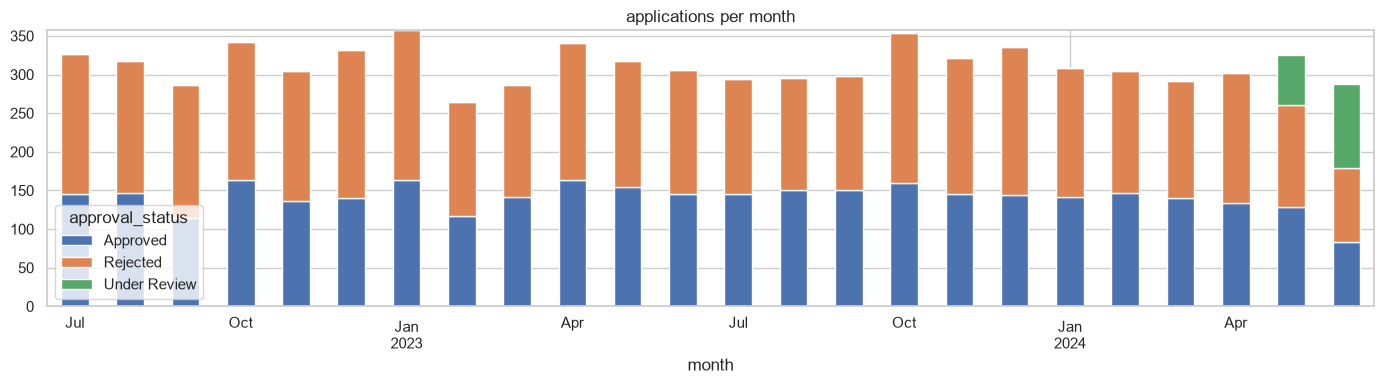

In [10]:
monthly = (loans.assign(month=loans["application_date"].dt.to_period("M"))
           .groupby(["month", "approval_status"]).size().unstack(fill_value=0))
monthly.plot(kind="bar", stacked=True, figsize=(14, 4), title="applications per month")
plt.tight_layout()
monthly.tail(3)

The approval rate drops in June 2024 but that's mostly because a lot of those
applications are still Under Review, not because more were rejected. Worth remembering
for the dashboard trend line.

## Default rate (disbursed loans only)

In [11]:
disbursed = loans[loans["loan_default"].notna()].copy()
disbursed["loan_default"] = disbursed["loan_default"].astype(int)
print("disbursed loans:", len(disbursed))
print("default rate:", round(disbursed["loan_default"].mean() * 100, 1), "%")

# one bureau row per customer so this join doesn't duplicate anything
df = (disbursed.merge(customers, on="customer_id", how="left")
               .merge(credit, on="customer_id", how="left"))
len(df)

disbursed loans: 3403
default rate: 23.4 %


3403

In [12]:
def default_rate(col):
    return df.groupby(col, observed=True)["loan_default"].agg(loans="count", default_rate="mean").round(3)

df["score_band"] = pd.cut(df["credit_score"], [299, 579, 649, 699, 749, 900],
                          labels=["<580", "580-649", "650-699", "700-749", "750+"])
df["dti_band"] = pd.cut(df["debt_to_income_ratio"], [0, 0.3, 0.5, 0.8, 10],
                        labels=["<0.3", "0.3-0.5", "0.5-0.8", "0.8+"])
df["util_band"] = pd.cut(df["credit_utilization_ratio"], [-0.01, 0.3, 0.6, 0.8, 1],
                         labels=["<0.3", "0.3-0.6", "0.6-0.8", "0.8+"])

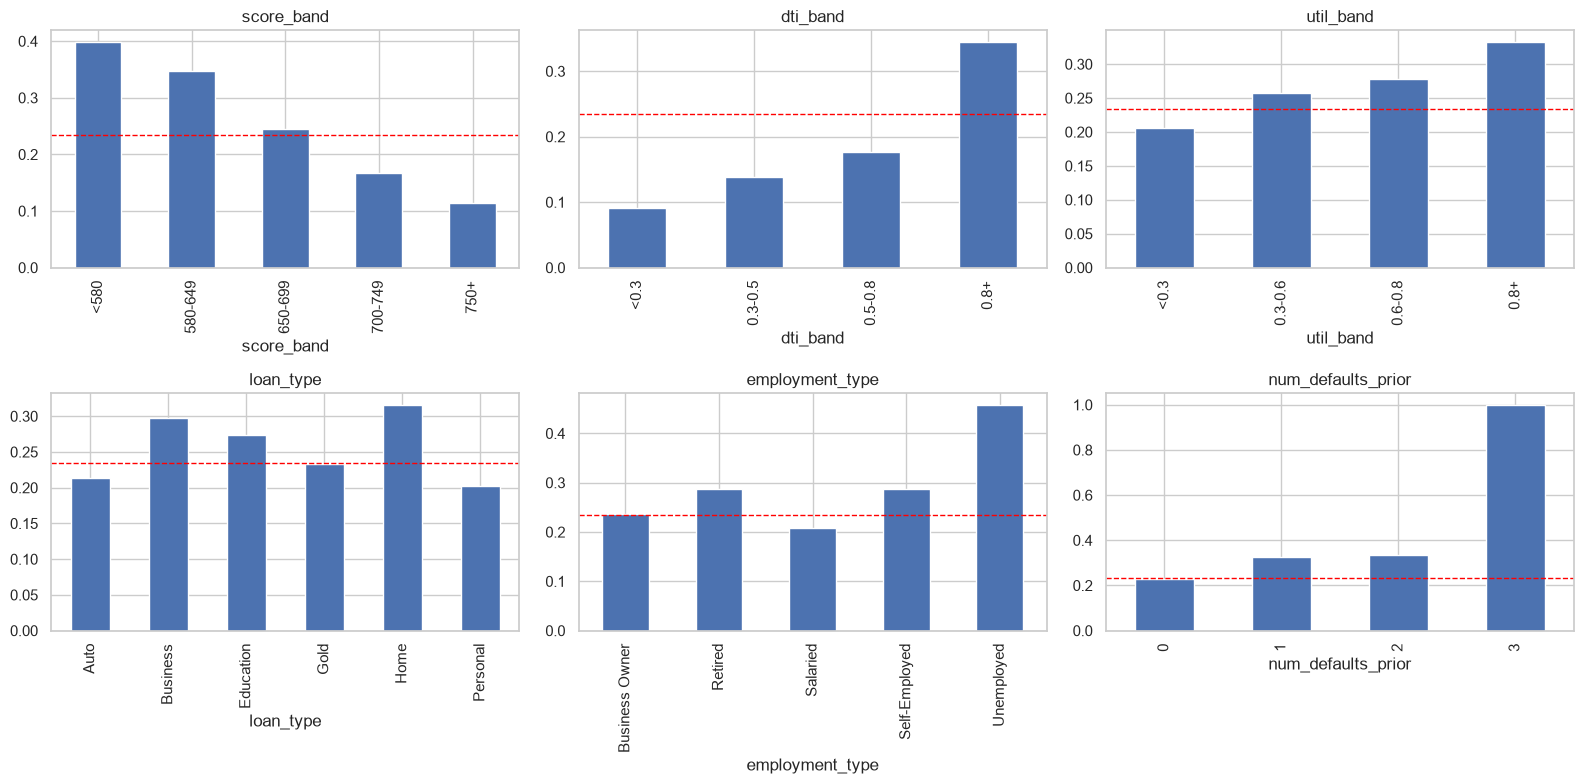

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["score_band", "dti_band", "util_band",
                               "loan_type", "employment_type", "num_defaults_prior"]):
    default_rate(col)["default_rate"].plot.bar(ax=ax, title=col)
    ax.axhline(df["loan_default"].mean(), color="red", ls="--", lw=1)
plt.tight_layout()

In [14]:
default_rate('score_band')

,loans,default_rate
score_band,,
<580,228,0.399
580-649,756,0.348
650-699,952,0.244
700-749,790,0.168
750+,677,0.115


In [15]:
default_rate('loan_type')

,loans,default_rate
loan_type,,
Auto,670,0.213
Business,290,0.297
Education,336,0.274
Gold,386,0.233
Home,326,0.316
Personal,1395,0.203


In [16]:
default_rate('employment_type')

,loans,default_rate
employment_type,,
Business Owner,477,0.237
Retired,163,0.288
Salaried,2041,0.208
Self-Employed,698,0.288
Unemployed,24,0.458


credit_score               -0.221726
annual_income              -0.173737
interest_rate              -0.059163
loan_term_months           -0.047632
age                        -0.012285
collateral_flag             0.023536
num_defaults_prior          0.051016
num_credit_inquiries_6m     0.056820
num_late_payments_90d       0.082801
credit_utilization_ratio    0.087718
requested_amount            0.118194
num_late_payments_30d       0.153894
debt_to_income_ratio        0.285654
Name: loan_default, dtype: float64

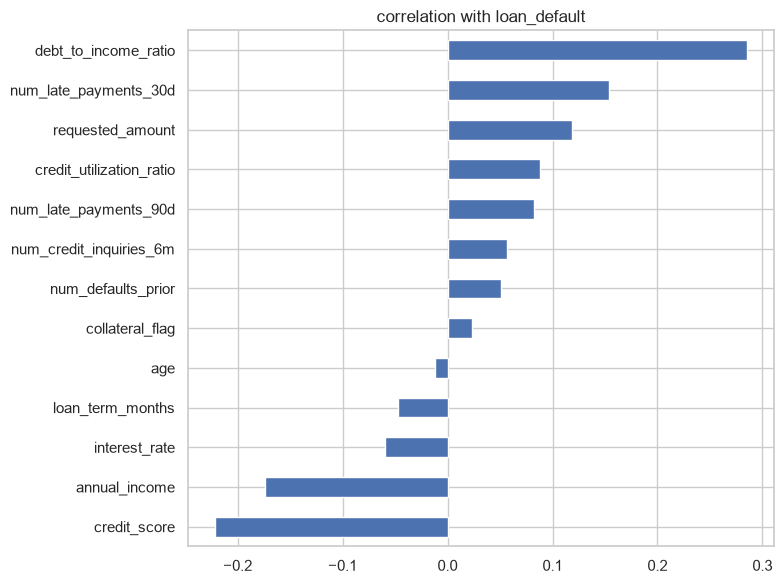

In [17]:
num_cols = ["age", "annual_income", "credit_score", "credit_utilization_ratio",
            "num_late_payments_30d", "num_late_payments_90d", "num_defaults_prior",
            "num_credit_inquiries_6m", "debt_to_income_ratio", "interest_rate",
            "requested_amount", "loan_term_months", "collateral_flag", "loan_default"]
corr = df[num_cols].corr()["loan_default"].drop("loan_default").sort_values()
corr.plot.barh(figsize=(8, 6), title="correlation with loan_default")
plt.tight_layout()
corr

## Geography

In [18]:
geo = df.groupby("state")["loan_default"].agg(loans="count", default_rate="mean").sort_values("loans", ascending=False)
geo.round(3)

,loans,default_rate
state,,
Maharashtra,508,0.236
Uttar Pradesh,366,0.210
Gujarat,350,0.231
Tamil Nadu,350,0.263
Karnataka,332,0.250
Madhya Pradesh,320,0.278
Delhi,198,0.187
Haryana,183,0.219
Telangana,172,0.180


## Transactions

2024-01-01 to 2024-06-29
txns per customer: {'count': 5000.0, 'mean': 8.0, 'std': 2.6, 'min': 4.0, '25%': 6.0, '50%': 8.0, '75%': 10.0, 'max': 12.0}


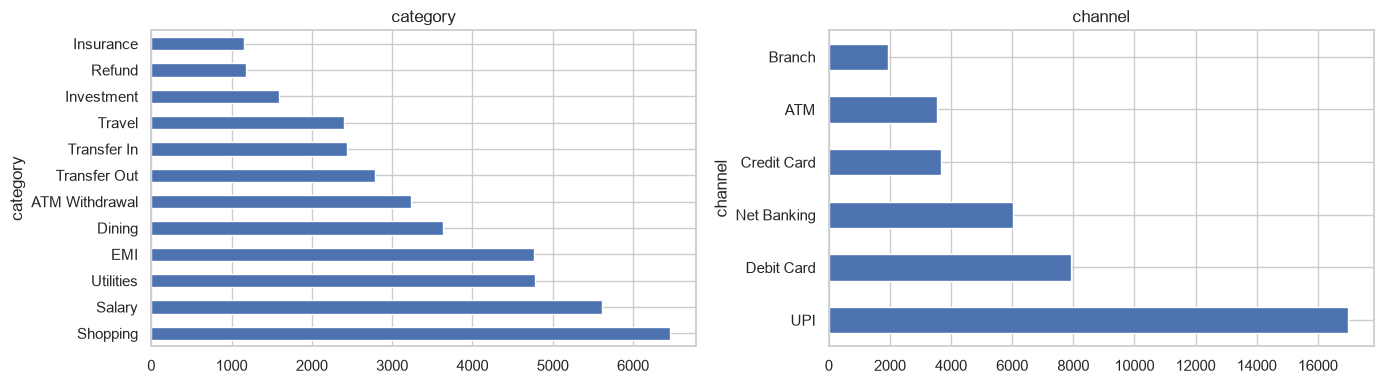

In [19]:
print(txns["transaction_date"].min().date(), "to", txns["transaction_date"].max().date())
print("txns per customer:", txns.groupby("customer_id").size().describe().round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
txns["category"].value_counts().plot.barh(ax=axes[0], title="category")
txns["channel"].value_counts().plot.barh(ax=axes[1], title="channel")
plt.tight_layout()

In [20]:
# quick look at whether cash flow says anything about default
flow = txns.pivot_table(index="customer_id", columns="transaction_type", values="amount", aggfunc="sum", fill_value=0)
flow["net_flow"] = flow["Credit"] - flow["Debit"]
flow["avg_balance"] = txns.groupby("customer_id")["balance_after"].mean()

tmp = df.merge(flow, on="customer_id", how="left")
tmp["net_flow_q"] = pd.qcut(tmp["net_flow"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
tmp.groupby("net_flow_q", observed=True)["loan_default"].mean().round(3)

net_flow_q
Q1 (lowest)     0.206
Q2              0.254
Q3              0.271
Q4 (highest)    0.207
Name: loan_default, dtype: float64

## Takeaways

- Data is clean: no orphan keys, no missing values except the expected ones.
- ~46% of decided applications approved, ~23% of disbursed loans defaulted.
- Debt-to-income is the strongest single signal (corr ~0.29), then credit score (~-0.22).
  Default rate goes from ~40% for scores under 580 down to ~12% for 750+.
- 30-day late payments, requested amount and income also matter. Prior defaults and
  utilization matter less than I expected.
- Home and Business loans default the most (~30%), Personal the least (~20%).
  Unemployed and self-employed borrowers default more than salaried ones.
- Net cash flow on its own doesn't show a clear pattern, will see if it helps in the model.
- Transactions are only ~8 per customer over 6 months so they need to be aggregated
  to one row per customer before joining onto loans.
- June 2024 has lots of Under Review apps, so the approval rate there looks low.